In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [5]:
df=pd.read_csv("loan_approval.csv")

In [6]:
df.head()

,income,credit_score,loan_amount,years_working,employment,loan_status
0,1320000,525,890000,11.0,Salaried,Rejected
1,1890000,749,400000,13.0,Self-employed,Approved
2,"13,80,000",622,390000,19.0,Salaried,Approved
3,1170000,530,910000,9.0,Self-employed,Rejected
4,690000,801,170000,0.0,Salaried,Approved


In [7]:
print(df.shape)
print(df.isnull().sum())
print("duplicate rows : ", df.duplicated().sum())
print(df.dtypes)

(152, 6)
income           0
credit_score     0
loan_amount      0
years_working    2
employment       0
loan_status      0
dtype: int64
duplicate rows :  2
income               str
credit_score       int64
loan_amount        int64
years_working    float64
employment           str
loan_status          str
dtype: object


In [8]:
print(df["employment"].value_counts())
print()
print(df["loan_status"].value_counts())

employment
Salaried         83
Self-employed    65
salaried          1
Self Employed     1
SALARIED          1
self-employed     1
Name: count, dtype: int64

loan_status
Rejected     77
Approved     72
approved      1
Rejected      1
REJECTED      1
Name: count, dtype: int64


In [9]:
df.describe().round(0)

,credit_score,loan_amount,years_working
count,152.0,152.0,150.0
mean,683.0,737500.0,9.0
std,398.0,460761.0,6.0
min,451.0,50000.0,0.0
25%,556.0,300000.0,4.0
50%,640.0,705000.0,9.0
75%,779.0,1187500.0,15.0
max,5330.0,1500000.0,20.0


In [10]:
df=df.drop_duplicates()
print(df.shape)

(150, 6)


In [11]:
df["income"] = df["income"].str.replace(",", "")
df["income"] = df["income"].str.replace(" ", "")

df["income"] = pd.to_numeric(df["income"])

print(df["income"].dtype)

int64


In [12]:
df[df["credit_score"]>900]

,income,credit_score,loan_amount,years_working,employment,loan_status
40,1770000,5330,1140000,16.0,Self-employed,Rejected


In [13]:
df.loc[df["credit_score"]>900,"credit_score"]=None
print(df["credit_score"].max())

845.0


In [14]:
credit_median=df["credit_score"].median()
years_median=df["years_working"].median()
df["credit_score"]=df["credit_score"].fillna(credit_median)
df["years_working"]=df["years_working"].fillna(years_median)
print("meadian credit score:",credit_median)
print("median years working:",years_median)
print("missing values left:",df.isnull().sum().sum())

meadian credit score: 646.0
median years working: 9.0
missing values left: 0


In [15]:
df["employment"]=df["employment"].str.strip()
df["employment"]=df["employment"].str.capitalize()

df["employment"]=df["employment"].replace({
    "Self-employed": "Self employment",
    "Self employed": "Self employment"
})
print(df["employment"].value_counts())

employment
Salaried           83
Self employment    67
Name: count, dtype: int64


In [16]:
df["employment"]=df["employment"].map({
    "Salaried": 1,
    "Self employment": 0
})
print(df["employment"].value_counts())

employment
1    83
0    67
Name: count, dtype: int64


In [17]:
df["loan_status"]=df["loan_status"].str.strip()
df["loan_status"]=df["loan_status"].str.capitalize()
print(df["loan_status"].value_counts())

loan_status
Rejected    78
Approved    72
Name: count, dtype: int64


In [18]:
df.groupby("loan_status").mean().round(2)

,income,credit_score,loan_amount,years_working,employment
loan_status,,,,,
Approved,1342638.89,724.94,582500.00,9.79,0.58
Rejected,1083461.54,586.73,888717.95,9.17,0.53


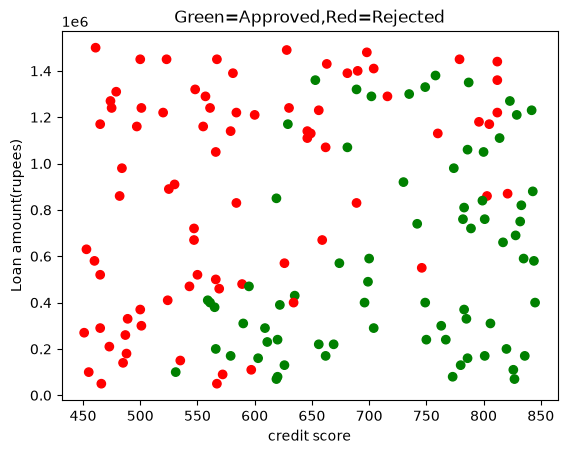

In [19]:
colours=df["loan_status"].map({"Approved":"Green","Rejected":"Red"})
plt.scatter(df["credit_score"],df["loan_amount"],c=colours)
plt.xlabel("credit score")
plt.ylabel("Loan amount(rupees)")
plt.title("Green=Approved,Red=Rejected")
plt.show()

In [20]:
X=df.drop(columns="loan_status")
y=df["loan_status"]


X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

print(X_train_scaled.shape)
print(X_test_scaled.shape)
print(y_test.value_counts().to_dict())

(120, 5)
(30, 5)
{'Rejected': 16, 'Approved': 14}


In [21]:
model=SVC(kernel="rbf",C=1)
model.fit(X_train_scaled,y_train)
print("model is trained")
print("support vector class:", model.n_support_)


model is trained
support vector class: [32 34]


In [22]:
y_pred = model.predict(X_test_scaled)
train_pred = model.predict(X_train_scaled)
print("train accuracy:",round(accuracy_score(y_train,train_pred),3))
print("test accuracy:",round(accuracy_score(y_test,y_pred),3))

train accuracy: 0.908
test accuracy: 0.933


In [23]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
cm_table=pd.DataFrame(cm,index=model.classes_,columns=model.classes_)
cm_table


,Approved,Rejected
Approved,13,1
Rejected,1,15


In [24]:
new_person=pd.DataFrame({
    "income" : [800000],
    "credit_score" : [760],
    "loan_amount" : [300000],
    "years_working" : [6],
    "employment" : [1]
})
new_scaled=scaler.transform(new_person)
print("decision:",model.predict(new_scaled)[0])

decision: Approved
